In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

In [2]:
# import the dataset
df = pd.read_csv("../data/Vapor_pressures.csv")
df.head()

,Name,CAS-RN,Formula,SMILES,T,Pvap,KDB_ID,Class,Subclass
0,METHANE,74-82-8,CH4,C,90.670000,11.702099,1,Paraffinic Hydrocarbons,n-Alkanes
1,METHANE,74-82-8,CH4,C,94.115172,17.886999,1,Paraffinic Hydrocarbons,n-Alkanes
2,METHANE,74-82-8,CH4,C,97.560345,26.489535,1,Paraffinic Hydrocarbons,n-Alkanes
3,METHANE,74-82-8,CH4,C,101.005517,38.137051,1,Paraffinic Hydrocarbons,n-Alkanes
4,METHANE,74-82-8,CH4,C,104.450690,53.534190,1,Paraffinic Hydrocarbons,n-Alkanes


In [3]:
df.shape

(41730, 9)

In [4]:
# EDA
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41730 entries, 0 to 41729
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      41730 non-null  str    
 1   CAS-RN    40170 non-null  str    
 2   Formula   41730 non-null  str    
 3   SMILES    41730 non-null  str    
 4   T         41730 non-null  float64
 5   Pvap      41730 non-null  float64
 6   KDB_ID    41730 non-null  int64  
 7   Class     41730 non-null  str    
 8   Subclass  41730 non-null  str    
dtypes: float64(2), int64(1), str(6)
memory usage: 5.9 MB


In [5]:
df.describe()

,T,Pvap,KDB_ID
count,41730.000000,4.173000e+04,41730.000000
mean,423.017430,5.585816e+02,1013.056075
std,138.683671,1.040175e+03,558.940333
min,2.000000,1.070000e-12,1.000000
25%,325.558621,4.795841e+00,604.000000
50%,412.073793,6.638848e+01,1057.000000
75%,513.839655,6.219602e+02,1471.000000
max,1113.000000,2.189791e+04,1943.000000


In [6]:
import datamol as dm

def get_fp(mol, fp_type='topological'):
    return dm.to_fp(mol, fp_type=fp_type)

df['Mol'] = df['SMILES'].apply(dm.to_mol)
df['Fingerprint'] = df['Mol'].apply(get_fp)

[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not removing hydrogen atom without neighbors
[09:48:24] WARNING: not r

In [7]:
df.Name.nunique()

1391

So we can see that there are 41370 rows but the name suggests only 1391 unique values, which means there are many same molecules at diff. temp and P

In [8]:
df.SMILES.nunique()

1384

In [9]:
df["T"].nunique()

36184

In [10]:
df.Class.nunique()

17

In [11]:
df.Subclass.nunique()

53

In [12]:
df.KDB_ID.nunique()

1391

Text(0.5, 9.444444444444441, 'Temperature [K]')

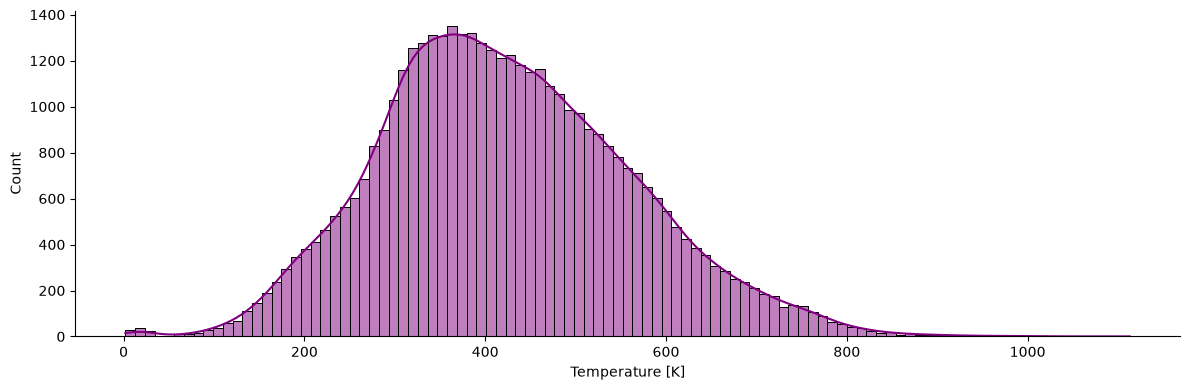

In [13]:
# Check temperature distribution

import seaborn as sns
sns.displot(df, kde = True, x = "T", legend= True, height=4, aspect=3, color = "purple")
plt.xlabel("Temperature [K]")

In [14]:
df['T'].skew()

np.float64(0.32183324253864964)

In [15]:
df['T'].kurtosis()

np.float64(0.07675710289490612)

Text(0.5, 9.444444444444441, 'Pressure [kPa]')

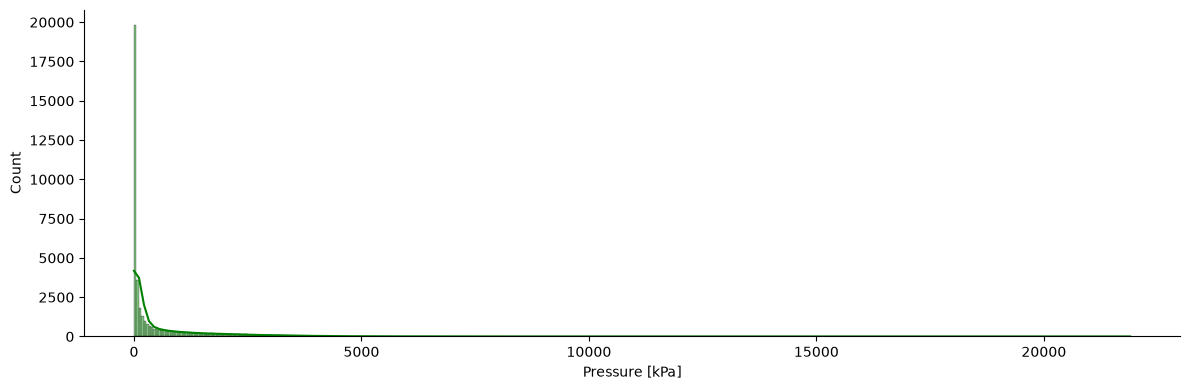

In [16]:
# Look for the pressure distribution
sns.displot(df, kde = True, x = "Pvap", legend= True, height=4, aspect=3, color = "green")
plt.xlabel("Pressure [kPa]")

In [17]:
df["Pvap"].skew()

np.float64(3.3246913533306564)

Text(0.5, 9.444444444444441, 'ln Pvap')

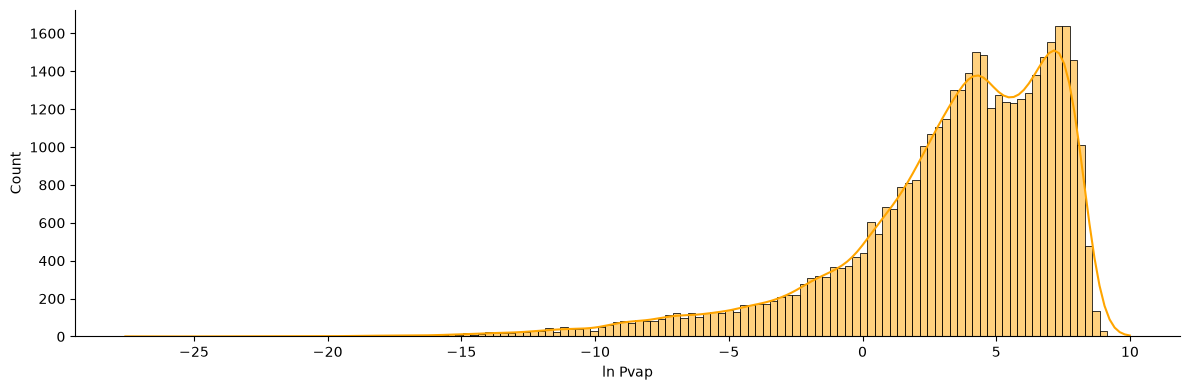

In [18]:
# Pvap is hugely skewed. Let's take log and see
df["ln_P"]=np.log(df.Pvap)
sns.displot(df, kde = True, x = "ln_P", legend= True, height=4, aspect=3, color = "orange")
plt.xlabel("ln Pvap")


In [19]:
df["ln_P"].skew()

np.float64(-1.5699673585057934)

In [20]:
df.Class.value_counts()

Class
Halogenated Derivatives       7110
Paraffinic Hydrocarbons       5100
Aromatics                     3660
Unsaturated Hydrocarbons      3630
Amines                        3480
Alcohols                      3060
Esters                        3030
Naphtenic Hydrocarbons        2190
Sulfur Derivatives            1860
Other Nitrogen Derivatives    1680
Acids                         1620
Ethers                        1500
Ketones                       1050
Inorganics                     960
Nitriles                       780
Aldehydes                      690
Amides                         330
Name: count, dtype: int64

In [21]:
# Splitting the dataset in such a way that the training data/compounds should not be in test data/compounds

from sklearn.model_selection import train_test_split
chemical_classes = df["Class"].unique() # 17 classes
# 3 different datasets
train_comps, valid_comps, test_comps = [], [], []
# Iterating through each class 
for cl in chemical_classes:
    # Get the data
    df_cl = df[df["Class"]==cl]

    # Get the unique compound for this class
    unique_compounds_cl = df_cl["Name"].unique().tolist()
    # Splitting for train, test
    train_all, comp_test = train_test_split(unique_compounds_cl, test_size = 0.20, random_state = 0)
    # split the train all to train and validation 
    comp_train, comp_valid = train_test_split(train_all, test_size = 0.20, random_state = 1)

    train_comps.extend(list(comp_train))
    valid_comps.extend(list(comp_valid))
    test_comps.extend(list(comp_test))

In [22]:
df_train = df[df['Name'].isin(train_comps)].reset_index()
df_valid = df[df['Name'].isin(valid_comps)].reset_index()
df_test = df[df['Name'].isin(test_comps)].reset_index()

In [23]:
df_train.head()

,index,Name,CAS-RN,Formula,SMILES,T,Pvap,KDB_ID,Class,Subclass,Mol,Fingerprint,ln_P
0,90,N-BUTANE,106-97-8,C4H10,CCCC,134.860000,0.000669,4,Paraffinic Hydrocarbons,n-Alkanes,<rdkit.Chem.rdchem.Mol object at 0x000002BAB96...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-7.309849
1,91,N-BUTANE,106-97-8,C4H10,CCCC,144.871035,0.003877,4,Paraffinic Hydrocarbons,n-Alkanes,<rdkit.Chem.rdchem.Mol object at 0x000002BAB96...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-5.552663
2,92,N-BUTANE,106-97-8,C4H10,CCCC,154.882069,0.017450,4,Paraffinic Hydrocarbons,n-Alkanes,<rdkit.Chem.rdchem.Mol object at 0x000002BAB96...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-4.048429
3,93,N-BUTANE,106-97-8,C4H10,CCCC,164.893103,0.064001,4,Paraffinic Hydrocarbons,n-Alkanes,<rdkit.Chem.rdchem.Mol object at 0x000002BAB96...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-2.748860
4,94,N-BUTANE,106-97-8,C4H10,CCCC,174.904138,0.198505,4,Paraffinic Hydrocarbons,n-Alkanes,<rdkit.Chem.rdchem.Mol object at 0x000002BAB96...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",-1.616940


In [24]:
print(df_train.shape)
print(df_valid.shape)
print(df_test.shape)

(26310, 13)
(6810, 13)
(8610, 13)


In [25]:
# Standardized the temp. values
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(df_train['T'].to_numpy().reshape(-1,1))

df_train['T_scaled'] = scaler.transform(df_train['T'].to_numpy().reshape(-1,1))
df_valid['T_scaled'] = scaler.transform(df_valid['T'].to_numpy().reshape(-1,1))
df_test['T_scaled'] = scaler.transform(df_test['T'].to_numpy().reshape(-1,1))

In [26]:
df_train.columns.tolist()

['index',
 'Name',
 'CAS-RN',
 'Formula',
 'SMILES',
 'T',
 'Pvap',
 'KDB_ID',
 'Class',
 'Subclass',
 'Mol',
 'Fingerprint',
 'ln_P',
 'T_scaled']

We are going to take fingerprint, scaled_T as X and ln_P as y.
Since the shape of fingerprint is very different, first change them to list and vertical stack them

In [27]:
df["Fingerprint"].tolist()

[array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0, 0, 0], shape=(2048,), dtype=uint8),
 array([0, 0, 0, ..., 0,

In [28]:
# Vertical stack sfter changing to numpy array
X_train= np.vstack(df_train["Fingerprint"].tolist())
X_train.shape

(26310, 2048)

In [29]:
# horizontal stack with the temperature
Ts_train = df_train['T_scaled'].to_numpy().reshape(-1,1)
Ts_train.shape
X_train = np.hstack((X_train, Ts_train))
X_train.shape


(26310, 2049)

In [30]:
# write a function to get X and y
def getX_y(A,):
    X = np.vstack(A["Fingerprint"].tolist())
    T = A["T_scaled"].to_numpy().reshape(-1,1)
    X = np.hstack((X, T))
    y = A['ln_P'].to_numpy().reshape(-1,1)
    return X, y


In [31]:
X_valid, y_valid = getX_y(df_valid)
X_test,  y_test  = getX_y(df_test)
X_train, y_train = getX_y(df_train)

In [32]:
print("X_valid shape: ", X_valid.shape)
print("y_valid shape: ", y_valid.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_valid shape:  (6810, 2049)
y_valid shape:  (6810, 1)
X_test shape:  (8610, 2049)
y_test shape:  (8610, 1)


In [33]:
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)

X_train shape:  (26310, 2049)
y_train shape:  (26310, 1)


Now that we have X and y, we can start building the Neural Network


In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(0)

# Build the function
class DNN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super(DNN, self).__init__()
        self.layer_1 = nn.Linear(in_dim, hidden_dim)
        self.layer_2 = nn.Linear(hidden_dim, hidden_dim)
        self.layer_3 = nn.Linear(hidden_dim, out_dim)

    def forward(self, x):
        x = F.relu(self.layer_1(x))
        x = F.relu(self.layer_2(x))
        x = self.layer_3(x)
        return x    

## Summary so far

**Goal:** predict $\ln P_{vap}$ of pure compounds from molecular structure and temperature, and test on compounds the model has never seen.

**Data preparation**
- Each SMILES string is converted to a molecular fingerprint (2048 bits). The fingerprint depends only on the molecule, so it is the same at every temperature.
- The target is $\ln P_{vap}$, which reduces the skewness from 3.3 (raw pressure) to -1.57.
- The data is split **by compound** within each chemical class (stratified), so no compound appears in more than one set: train 26,310 rows, validation 6,810 rows, test 8,610 rows.
- Temperature is standardized with a scaler fitted on the training set only, to avoid data leakage.
- Model input $X$ = fingerprint + scaled temperature (2049 features). Target $y$ = $\ln P_{vap}$, shape $(n, 1)$.

**Network architecture (DNN)**

Linear(2049 → hidden) → ReLU → Linear(hidden → hidden) → ReLU → Linear(hidden → 1)

- Two hidden layers, which makes the network deep.
- No activation on the output, since $\ln P$ can be any real number.
- Trainable parameters: $(2049 \times h + h) + (h \times h + h) + (h + 1)$, where $h$ is the hidden size.

**Next:** train the network, check for overfitting using the validation set, apply early stopping, tune the hidden size, and evaluate on the test set.

In [35]:
# Initialize the model 
model = DNN(X_train.shape[1], 20, 1)

In [36]:
# Check for model parameters
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model)

41441

In [37]:
print(model)

DNN(
  (layer_1): Linear(in_features=2049, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=20, bias=True)
  (layer_3): Linear(in_features=20, out_features=1, bias=True)
)


In [38]:
# Define the loss function
loss_function = nn.MSELoss()
# Define the optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

In [39]:
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# model = model.to(device)
# X_train_torch = torch.from_numpy(X_train).float().to(device)
# print(device)

In [40]:
n_epochs = 250
# Change to tensor
X_train_torch = torch.from_numpy(X_train).float()
y_train_torch = torch.from_numpy(y_train).float()

X_valid_torch = torch.from_numpy(X_valid).float()
y_valid_torch = torch.from_numpy(y_valid).float()

losses = np.zeros((n_epochs, 2))

for epoch in tqdm(range(n_epochs)):
    model.train()
    # Forward propagation
    y_pred_train = model(X_train_torch)
    loss = loss_function(y_pred_train, y_train_torch)
    losses[epoch, 0] = loss.item()

    # Backward Propagation
    model.zero_grad()
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Evaluate model in validation set
    model.eval()
    with torch.no_grad():
        y_pred_valid = model(X_valid_torch)
        loss = loss_function(y_pred_valid, y_valid_torch)
        losses[epoch, 1] = loss.item()


C:\Users\user\AppData\Local\Temp\ipykernel_6296\255963682.py:4: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y_train_torch = torch.from_numpy(y_train).float()


  0%|          | 0/250 [00:00<?, ?it/s]

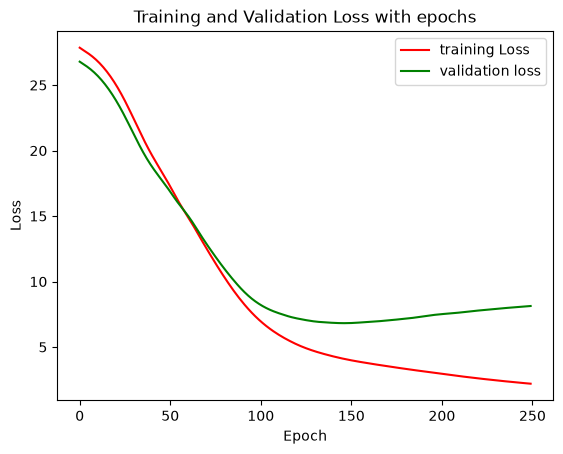

In [41]:
plt.figure()
plt.plot(losses[:, 0], label = "training Loss", color = 'red')
plt.plot(losses[:, 1], label = "validation loss", color = 'green')
plt.title("Training and Validation Loss with epochs")
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [42]:
# Early Stopping
import copy
import torch
import torch.nn as nn

class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience      # epochs to wait for a new best
        self.min_delta = min_delta    # smallest improvement that counts
        self.best_loss = float("inf")
        self.counter = 0
        self.best_state = None        # snapshot of the best weights

    def step(self, val_loss, model):
        """Call once per epoch. Returns True when training should stop."""
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
        return self.counter >= self.patience

In [43]:
# Training again with early stopping

model_early = DNN(X_train.shape[1], 20, 1)
loss_function = nn.MSELoss()
# Define the optimizer
optimizer = torch.optim.Adam(model_early.parameters(), lr=0.002)
losses_early = np.zeros((n_epochs, 2))

stopper = EarlyStopping(patience=30)
for epoch in tqdm(range(n_epochs)):
    model_early.train()
    # Forward propagation
    y_pred_train = model_early(X_train_torch)
    loss = loss_function(y_pred_train, y_train_torch)
    losses_early[epoch, 0] = loss.item()

    # Backward Propagation
    model_early.zero_grad()
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Evaluate model in validation set
    model_early.eval()
    with torch.no_grad():
        y_pred_valid = model_early(X_valid_torch)
        loss_valid = loss_function(y_pred_valid, y_valid_torch)
        losses_early[epoch, 1] = loss_valid.item()

    if stopper.step(loss_valid, model_early):
        print(f"Stopped at epoch {epoch}, best val loss {stopper.best_loss:.4f}")
        break

# go back to the best weights, not the last ones
model_early.load_state_dict(stopper.best_state)    

  0%|          | 0/250 [00:00<?, ?it/s]

<All keys matched successfully>

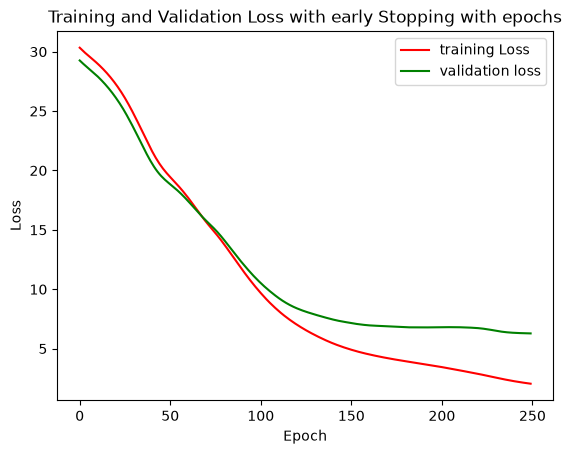

In [44]:
plt.figure()
plt.plot(losses_early[:epoch+1, 0], label = "training Loss", color = 'red')
plt.plot(losses_early[:epoch+1, 1], label = "validation loss", color = 'green')
plt.title("Training and Validation Loss with early Stopping with epochs")
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [45]:
print(stopper.best_loss)            # best validation loss
print(epoch - stopper.patience)     # epoch where it was reached

tensor(6.2819)
219


In [46]:
from sklearn.metrics import mean_absolute_percentage_error as MAPE
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import r2_score as R2

X_test_torch = torch.from_numpy(X_test).float()

model_early.eval()
with torch.no_grad():
    y_test_pred = model_early(X_test_torch).numpy()

print('MAPE: ', MAPE(y_test, y_test_pred)*100)
print('MAE : ', MAE(y_test, y_test_pred))
print('R2  : ', R2(y_test, y_test_pred))

MAPE:  160.3247619563178
MAE :  1.6470969402084459
R2  :  0.6665815448866377


In [47]:
# Hyperparameter Tuning of the hidden layer

hidden_size = [3, 10, 20, 50, 100]

n_epochs = 250
param_list = []
valid_mape_list = []
models = []
torch.manual_seed(0)

# Iterate over the hidden sizes
for hs in hidden_size:
    model = DNN(X_train.shape[1], hs, 1)
    optimizer = torch.optim.Adam(model.parameters(), lr = 0.002)
    model_params = count_parameters(model)
    print('Hidden-size: ', hs)
    print('Model parameters: ', model_params)

    losses = np.zeros((n_epochs, 2))
    for epoch in tqdm(range(n_epochs)):
        model.train()
        # Forward propagation 
        y_train_pred = model(X_train_torch)
        loss = loss_function(y_train_pred, y_train_torch)
        losses[epoch, 0] = loss.item()

        # Backward propagation
        model.zero_grad()
        loss.backward()

        # Update model parameters
        optimizer.step()

    # Evaluate the final model in the validation set
    models.append(model)
    model.eval()
    with torch.no_grad():
        y_valid_pred = model(X_valid_torch)
        mape = MAPE(y_valid_torch, y_valid_pred,)* 100
    param_list.append(model_params)
    valid_mape_list.append(mape)    

    



Hidden-size:  3
Model parameters:  6166


  0%|          | 0/250 [00:00<?, ?it/s]

Hidden-size:  10
Model parameters:  20621


  0%|          | 0/250 [00:00<?, ?it/s]

Hidden-size:  20
Model parameters:  41441


  0%|          | 0/250 [00:00<?, ?it/s]

Hidden-size:  50
Model parameters:  105101


  0%|          | 0/250 [00:00<?, ?it/s]

Hidden-size:  100
Model parameters:  215201


  0%|          | 0/250 [00:00<?, ?it/s]

In [48]:
best_idx = np.argmin(valid_mape_list)
print('Best hidden size: ', hidden_size[best_idx])
print('Valid MAPE', valid_mape_list[best_idx])

Best hidden size:  10
Valid MAPE 101.66645050048828


In [49]:
best_model = models[best_idx]
best_model.eval()
with torch.no_grad():
    y_test_pred = best_model(X_test_torch).numpy()

print('MAPE: ', MAPE(y_test, y_test_pred)*100)
print('MAE : ', MAE(y_test, y_test_pred))
print('R2  : ', R2(y_test, y_test_pred))

MAPE:  107.58420288817356
MAE :  1.8622251672713186
R2  :  0.5835543287506505


In [50]:
print(param_list)
print(valid_mape_list)
print(models) 

[6166, 20621, 41441, 105101, 215201]
[122.66103029251099, 101.66645050048828, 146.4708924293518, 137.55087852478027, 129.80345487594604]
[DNN(
  (layer_1): Linear(in_features=2049, out_features=3, bias=True)
  (layer_2): Linear(in_features=3, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
), DNN(
  (layer_1): Linear(in_features=2049, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
), DNN(
  (layer_1): Linear(in_features=2049, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=20, bias=True)
  (layer_3): Linear(in_features=20, out_features=1, bias=True)
), DNN(
  (layer_1): Linear(in_features=2049, out_features=50, bias=True)
  (layer_2): Linear(in_features=50, out_features=50, bias=True)
  (layer_3): Linear(in_features=50, out_features=1, bias=True)
), DNN(
  (layer_1): Linear(in_features=2049, out_features=100, b

In [52]:
# Doing the hyperparamter sear with early stopping
# Hyperparameter Tuning of the hidden layer
import pandas as pd
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import mean_absolute_percentage_error as MAPE
from sklearn.metrics import mean_squared_error
hidden_size = [3, 10, 20, 50]

n_epochs = 250
results = []     # one row per hidden size, for the table
curves = {}      # loss curves per size, for plotting
models = {}      # trained models per size

# Iterate over the hidden sizes
for hs in hidden_size:
    torch.manual_seed(0) 
    model_E = DNN(X_train.shape[1], hs, 1)
    optimizer = torch.optim.Adam(model_E.parameters(), lr = 0.002)
    model_E_params = count_parameters(model_E)
    stopper = EarlyStopping(patience=30)
    n_params = count_parameters(model_E)
    print('Hidden-size:', hs, '| Model parameters:', n_params)

    losses = np.zeros((n_epochs, 2))
    for epoch in tqdm(range(n_epochs)):
        model_E.train()
        # Forward propagation 
        y_train_pred = model_E(X_train_torch)
        loss = loss_function(y_train_pred, y_train_torch)
        losses[epoch, 0] = loss.item()

        # Backward propagation
        model_E.zero_grad()
        loss.backward()

        # Update model parameters
        optimizer.step()

        model_E.eval()
        with torch.no_grad():
            y_valid_pred = model_E(X_valid_torch)
            loss_valid = loss_function(y_valid_pred, y_valid_torch)
            losses[epoch, 1] = loss_valid.item()
        
        if stopper.step(loss_valid.item(), model_E):
            print(f"Stopped at epoch {epoch}, best val loss {stopper.best_loss:.4f}")
            break


    best_epoch = epoch - stopper.counter                   # epochs since the best one
    model_E.load_state_dict(stopper.best_state)            # go back to the best weights

    # Validation metrics from the restored model
    model_E.eval()
    with torch.no_grad():
        pred = model_E(X_valid_torch).numpy()
    true = y_valid_torch.numpy()

    results.append({
        'hidden_size': hs,
        'parameters': n_params,
        'stopped_epoch': epoch,
        'best_epoch': best_epoch,
        'val_MSE': stopper.best_loss,
        'val_MAE': MAE(true, pred),
        'val_RMSE': np.sqrt(mean_squared_error(true, pred)),
        'val_MAPE_%': MAPE(true, pred) * 100,
    })
    curves[hs] = losses[:epoch + 1]
    models[hs] = model_E

results_df = pd.DataFrame(results)
results_df
       

    



Hidden-size: 3 | Model parameters: 6166


  0%|          | 0/250 [00:00<?, ?it/s]

Hidden-size: 10 | Model parameters: 20621


  0%|          | 0/250 [00:00<?, ?it/s]

Stopped at epoch 226, best val loss 6.9170
Hidden-size: 20 | Model parameters: 41441


  0%|          | 0/250 [00:00<?, ?it/s]

Stopped at epoch 176, best val loss 6.8239
Hidden-size: 50 | Model parameters: 105101


  0%|          | 0/250 [00:00<?, ?it/s]

Stopped at epoch 189, best val loss 6.2081


,hidden_size,parameters,stopped_epoch,best_epoch,val_MSE,val_MAE,val_RMSE,val_MAPE_%
0,3,6166,249,249,11.192066,2.513540,3.345455,122.661030
1,10,20621,226,196,6.916964,1.877803,2.630012,107.045686
2,20,41441,176,146,6.823932,1.865003,2.612266,107.561243
3,50,105101,189,159,6.208094,1.712894,2.491605,135.279548


In [53]:
# Check on the test set
final_model = models[50]
final_model.eval()

X_test_torch = torch.from_numpy(X_test).float()

with torch.no_grad():
    y_test_pred = final_model(X_test_torch).numpy()

print('MAE  :', MAE(y_test, y_test_pred))
print('RMSE :', np.sqrt(mean_squared_error(y_test, y_test_pred)))
print('R2   :', R2(y_test, y_test_pred))
print('MAPE :', MAPE(y_test, y_test_pred) * 100, '(secondary)')

MAE  : 1.6343028977328276
RMSE : 2.51640716571329
R2   : 0.6422783361875049
MAPE : 146.59735854826604 (secondary)
